# 04 - Clustering arena (Mall Customers)
No ground-truth labels exist, so we judge clusterings by internal metrics (silhouette on non-noise points, Davies-Bouldin), cluster counts, noise fraction, and **stability under noise** (ARI against the clean clustering). Features: standardized Annual Income + Spending Score ('2d'); '3d' adds Age.

In [1]:
import sys, json; sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from arena.config import RAW_DIR, SUMMARY_DIR, PRED_DIR
pd.set_option('display.width', 180)
raw = pd.read_csv(RAW_DIR/'clustering.csv'); sel = pd.read_csv(SUMMARY_DIR/'clustering_selected.csv')
stab = pd.read_csv(SUMMARY_DIR/'clustering_stability_summary.csv')
lab = pd.read_csv(PRED_DIR/'clustering_labels.csv'); mall = pd.read_csv('../data/raw/mall/Mall_Customers.csv')

## Selected configuration per algorithm (max silhouette; DBSCAN limited to <=30% noise)

In [2]:
sel.drop(columns=['params_json']).assign(params=sel.params_json).round(3)

,features,algorithm,n_clusters,noise_frac,silhouette,davies_bouldin,params
0,2d,kmeans,5,0.000,0.555,0.572,"{""k"": 5}"
1,2d,meanshift,7,0.000,0.529,0.621,"{""bandwidth"": 0.6487582521320147, ""quantile"": ..."
2,2d,agg_single,2,0.000,0.434,0.372,"{""k"": 2}"
3,2d,dbscan,7,0.175,0.524,0.580,"{""eps"": 0.3, ""min_samples"": 5}"
4,3d,kmeans,6,0.000,0.427,0.828,"{""k"": 6}"
5,3d,meanshift,7,0.000,0.415,0.845,"{""bandwidth"": 1.0149139013232393, ""quantile"": ..."
6,3d,agg_single,2,0.000,0.251,0.580,"{""k"": 2}"
7,3d,dbscan,6,0.300,0.482,0.639,"{""eps"": 0.5, ""min_samples"": 5}"


## Sweep: silhouette vs. k (K-means, single linkage)

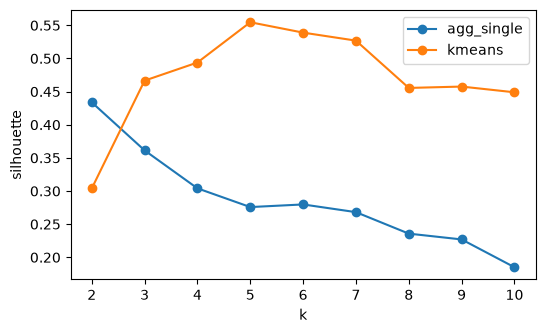

In [3]:
d = raw[(raw.features=='2d') & raw.algorithm.isin(['kmeans','agg_single'])].copy(); d['k'] = d.params_json.map(lambda s: json.loads(s)['k'])
fig, ax = plt.subplots(figsize=(6,3.5))
for a, g in d.groupby('algorithm'):
    g = g.groupby('k').silhouette.mean(); ax.plot(g.index, g.values, marker='o', label=a)
ax.set_xlabel('k'); ax.set_ylabel('silhouette'); ax.legend(); plt.show()

Single linkage chains: it peels off a few outliers first, so its silhouette is best at k=2 (one or a few outlier points vs. everyone else). That is **the chaining effect**, not a good segmentation.

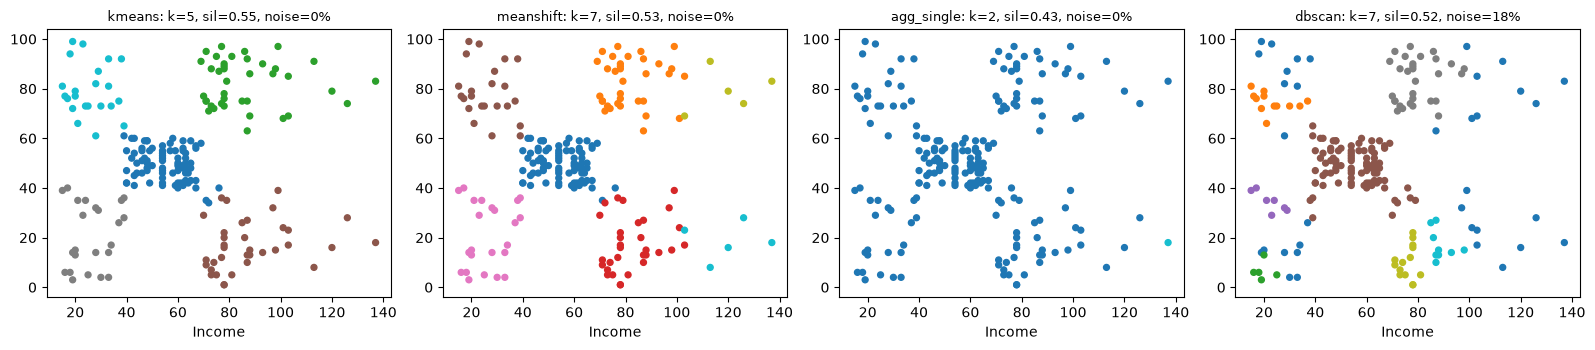

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, a in zip(axes, ['kmeans','meanshift','agg_single','dbscan']):
    ax.scatter(mall['Annual Income (k$)'], mall['Spending Score (1-100)'], c=lab[a+'_2d'], cmap='tab10', s=18)
    s = sel[(sel.features=='2d') & (sel.algorithm==a)].iloc[0]; ax.set_title(f"{a}: k={s.n_clusters}, sil={s.silhouette:.2f}, noise={s.noise_frac:.0%}", fontsize=9)
    ax.set_xlabel('Income'); 
plt.tight_layout()

## Stability under noise (ARI vs. clean clustering; 1.0 = identical)

algorithm  agg_single  dbscan  kmeans  meanshift
sigma                                           
0.10            0.195   0.788   0.952      0.920
0.25            0.396   0.559   0.852      0.754
0.50            0.196   0.328   0.499      0.342


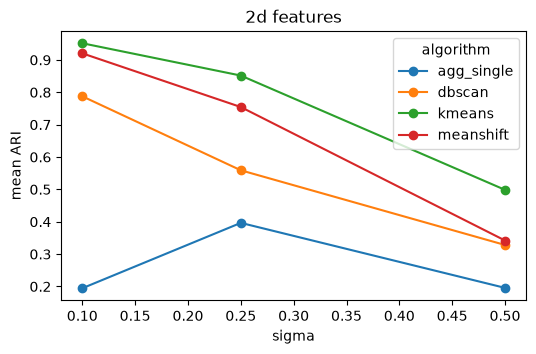

In [5]:
p = stab[stab.features=='2d'].pivot(index='sigma', columns='algorithm', values='ari_mean'); print(p.round(3)); p.plot(marker='o', figsize=(6,3.5)); plt.ylabel('mean ARI'); plt.title('2d features'); plt.show()

Single-linkage ARI is erratic (huge std): whether it isolates the same outliers changes with the noise draw. Compare with k-means in the table above. (H6 verdict is computed in the report notebook step on Day 4.)